# Server reader: every model we trained, and what each step contributed

**Read-only.** This notebook reads saved predictions; it starts no training, inference or download. Run it top to bottom on the Mac.

It answers one question for the server recognizer (PP-OCRv5_server_rec): **how did we get from the downloaded model to the final one, and which changes actually helped?**

- Sections 1–3: every model, one table, the step-by-step progression (our split).
- Section 4: training strategies with two seeds (S0–S3, G0).
- Section 5: unfamiliar handwriting (two new writers; the 11 Nov fresh boards).
- Section 6: the final model on the teammate's 80:10:10 split (S1his).
- Section 7: summary of what contributed.

**One scorer.** The checks below confirm that every experiment read the same crops with the same labels, and that the untouched pretrained model (and the historical V1) produced *identical* readings in every experiment. So numbers from different days can sit in one table. Mean line CER, case-insensitive, spaces normalised; lower is better.

In [1]:
from pathlib import Path
from collections import defaultdict
import csv, json, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ASSIGNMENT_OVERRIDE = None
roots = [p for base in [Path.cwd(), *Path.cwd().parents] for p in (base, base / 'Assignment')]
if ASSIGNMENT_OVERRIDE: roots.insert(0, Path(ASSIGNMENT_OVERRIDE).expanduser())
A = next((p.resolve() for p in roots if (p / 'results_versions_2x2/results/predictions.csv').is_file()), None)
assert A is not None, 'Set ASSIGNMENT_OVERRIDE to the Assignment folder.'

load = lambda rel: pd.read_csv(A / rel, keep_default_na=False)
dv = load('results_versions_2x2/results/predictions.csv')      # 6 Nov: pretrained, V1, V1b, V2short, V3short, V2, V3, C1, P40, P128
ds = load('results_strategies_s0s3/results/predictions.csv')   # 7 Nov: S0-S3, 2 seeds
dg = load('results_guide_g0/results/predictions.csv')          # 7 Nov: G0, 2 seeds
dc = load('results_server_c0_20261111/results/predictions.csv')# 11 Nov: C0
SETS = ['whiteboard val', 'CNN test', 'long sentences (held out)', 'new writers', 'IAM val']

# 1. the untouched pretrained model and V1 read identically in every experiment -> same scorer
def readings(d, m):
    x = d[d.model.eq(m)]
    return dict(zip(zip(x['set'], x.file), zip(x.label, x.pred)))
for m in ('pretrained', 'V1'):
    a, b, c = readings(dv, m), readings(ds, m), readings(dg, m)
    for x, y, tag in ((a, b, '6 Nov vs 7 Nov'), (b, c, 'strategies vs guidance')):
        common = set(x) & set(y)
        assert common and all(x[k] == y[k] for k in common), f'{m}: readings differ ({tag})'
c0 = json.loads((A / 'results_server_c0_20261111/results/summary.json').read_text())
assert c0['pretrained_identical'] == 1.0, 'C0 was not scored with the same reader setup'

keep_v = dv[dv.model.isin(['pretrained', 'V1', 'V1b', 'V2short', 'V3short', 'V2', 'V3', 'C1', 'P40', 'P128'])]
keep_s = ds[ds.model.isin(['S0', 'S0s2', 'S1', 'S1s2', 'S2', 'S2s2', 'S3', 'S3s2', 'S0avg', 'S1avg', 'S2avg', 'S3avg'])]
keep_g = dg[dg.model.isin(['G0', 'G0s2', 'G0avg'])]
keep_p = ds[ds.model.isin(['pretrained', 'V1']) & ds['set'].eq('new writers')]   # the new-writer set was added on 7 Nov
df = pd.concat([keep_v, keep_p, keep_s, keep_g, dc], ignore_index=True)
df = df[df['set'].isin(SETS)]
assert not df.duplicated(['model', 'set', 'file']).any()
# 2. every model scored the same crops and labels in each set it has
for st in SETS:
    sig = {m: frozenset(zip(g.file, g.label)) for m, g in df[df['set'].eq(st)].groupby('model')}
    assert len(set(sig.values())) == 1, f'different crops or labels in {st}'
MEAN = df.groupby(['model', 'set']).cer.mean() * 100

def boot(a, b, st, n=2000):
    '''A - B on the same crops; 95% interval resampling whole photos (whole sentences for the long set), seed 0.'''
    ra = df[df.model.eq(a) & df['set'].eq(st)]; B = dict(zip(*[df[df.model.eq(b) & df['set'].eq(st)][k] for k in ('file', 'cer')]))
    g = defaultdict(list)
    for f, cl, c in zip(ra.file, ra.cluster, ra.cer): g[cl].append(c - B[f])
    G = list(g.values()); mean = lambda gs: sum(map(sum, gs)) / sum(map(len, gs)); rng = random.Random(0)
    s = sorted(mean([G[rng.randrange(len(G))] for _ in G]) for _ in range(n))
    return 100 * mean(G), 100 * s[int(.025 * n)], 100 * s[int(.975 * n) - 1]

def cell(a, b, st):
    if (a, st) not in MEAN.index or (b, st) not in MEAN.index: return ''
    d, lo, hi = boot(a, b, st)
    return f'{d:+.2f} [{lo:+.2f}, {hi:+.2f}]' + (' better' if hi < 0 else ' worse' if lo > 0 else '')

plt.rcParams.update({'figure.dpi': 115, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor': 'white'})
pd.set_option('display.max_colwidth', 120)
print('Assignment folder:', A)
print('Checks passed: pretrained and V1 read identically in every experiment; every model scored the same crops and labels.')

Assignment folder: /Users/zhaobao/Documents/SIT/SIT-Y2-Tri1/Computer Vision & Deep Learning/Assignment
Checks passed: pretrained and V1 read identically in every experiment; every model scored the same crops and labels.


## 1. Every server model we trained

Every run starts from the **same downloaded pretrained weights** and gets about **6,000 updates of 16 crops**, so the runs differ only in what the table says. They are separate experiments, not successive stages of one checkpoint.

| model | date | training data | recipe | question it answers |
|---|---|---|---|---|
| pretrained | — | none (as downloaded) | 48 px, read at full width | the starting point |
| V1 | 13 Oct | historical baseline model | as deployed then | project history only |
| V1b | 6 Nov | IAM paper handwriting only | adapted | is general handwriting enough? |
| **C0** | 11 Nov | our crops (no copies), lines that fit 40 positions | **original** 48×320, 40 positions | fine-tuning on our data, PaddleOCR's own recipe |
| C1 | 6 Nov | C0's crops + our augmented copies | original | do pre-made copies help? |
| P40 | 6 Nov | same lines as C1 | 64×1024 input, still 40 positions | a wider input on its own |
| **P128** | 6 Nov | same lines as C1 | 64×1024, **width/8 positions** | our pooling change |
| V3short / V2short | 6 Nov | short lines, with / without copies | adapted | copies on short lines |
| V3 | 6 Nov | all lines + copies | adapted | + long lines |
| **V2** | 6 Nov | all lines, no copies | adapted | long lines without copies |
| **S0** (2 seeds) | 7 Nov | V2's lines **minus 64 teammate crops** | adapted | clean baseline (new-writer test stays unseen) |
| **S1** (2 seeds) | 7 Nov | S0's lines | + stage-wise learning rates | protect pretrained low-level features |
| S2 (2 seeds) | 7 Nov | S0's lines | + focal CTC | weight hard lines more |
| S3 (2 seeds) | 7 Nov | S0's lines | S1 + S2 | do they add up? |
| **G0** (2 seeds) | 7 Nov | S0's lines | + guidance off | let the CTC loss train the backbone |
| **S1his** | 10 Nov | teammate's leak-fixed 80:10:10 train | S1 recipe | the final model (section 6) |

"Adapted" = our recipe: 64×1024 input, width/8 training positions, full-height reading pooling. "Our crops" = our whiteboard training boards plus the training part of the long-sentence collection.

In [2]:
runs = []
for exp, folder in [('6 Nov', 'results_versions_2x2'), ('7 Nov', 'results_strategies_s0s3'), ('7 Nov', 'results_guide_g0'),
                    ('11 Nov', 'results_server_c0_20261111'), ('10 Nov', 'results_server_his_20261110')]:
    for d in sorted((A / folder / 'runs').glob('*/DONE')):
        if d.parent.name.startswith('smoke'): continue
        j = json.loads(d.read_text()); p = j['plan']
        runs.append({'model': d.parent.name, 'date': exp, 'training lines': p['lines'], 'epochs': p['epochs'],
                     'updates': p['planned_updates'], 'GPU minutes': j['minutes']})
display(Markdown('**Training budget actually used (from each run\'s DONE record).** Fewer lines means more epochs, so every run gets about the same number of updates.'))
display(pd.DataFrame(runs).set_index('model'))

**Training budget actually used (from each run's DONE record).** Fewer lines means more epochs, so every run gets about the same number of updates.

,date,training lines,epochs,updates,GPU minutes
model,,,,,
C1,6 Nov,4269,22,5874,6.5
P128,6 Nov,4269,22,5874,21.3
P40,6 Nov,4269,22,5874,12.9
V1b,6 Nov,6482,15,6090,22.0
V2,6 Nov,1423,67,5963,23.9
V2short,6 Nov,1118,86,6020,23.2
V3,6 Nov,5500,17,5848,21.9
V3short,6 Nov,4289,22,5918,21.6
S0,7 Nov,1359,71,6035,23.2


## 2. One table: every model on the same crops

Mean line CER (%). Blank = not scored on that set. The **new-writer** set (two people, JH and DS) was added on 7 Nov, so the 6 Nov runs have no GPU score for it; C0 is shown there but it trained on the 64 teammate crops, whose writers may be the test writers. S0–S3 and G0 are the **mean of two seeds**.

In [3]:
ORDER = ['pretrained', 'V1', 'V1b', 'C0', 'C1', 'P40', 'P128', 'V2short', 'V3short', 'V3', 'V2', 'S0avg', 'S1avg', 'S2avg', 'S3avg', 'G0avg']
table = pd.DataFrame({st: [MEAN.get((m, st), np.nan) for m in ORDER] for st in SETS}, index=ORDER)
table.index.name = 'model'
display(table.rename(columns=lambda c: c + ' CER (%)').round(2))
best = table.drop(index=['pretrained', 'V1']).idxmin()
display(Markdown('Lowest CER per set (fine-tuned models): ' + ', '.join(f'**{st}**: {m}' for st, m in best.items()) + '.'))

,whiteboard val CER (%),CNN test CER (%),long sentences (held out) CER (%),new writers CER (%),IAM val CER (%)
model,,,,,
pretrained,15.48,45.79,30.93,43.08,12.20
V1,90.59,81.32,84.94,89.80,79.46
V1b,16.77,49.76,5.79,NaN,7.79
C0,8.88,29.00,7.84,42.38,30.57
C1,9.30,28.72,8.81,NaN,31.40
P40,54.54,93.88,45.26,NaN,60.98
P128,6.44,26.60,4.55,NaN,21.68
V2short,7.25,28.57,5.81,NaN,27.06
V3short,7.13,25.83,4.49,NaN,21.08


Lowest CER per set (fine-tuned models): **whiteboard val**: P128, **CNN test**: V2, **long sentences (held out)**: S3avg, **new writers**: G0avg, **IAM val**: V1b.

## 3. The progression, one change at a time

Each step changes **one** thing (checked by data-list hashes when the runs were made). Values are A − B in percentage points with a 95 % interval that resamples whole photos (whole sentences for the long set). Negative = the change lowered the error. "better" / "worse" only when the whole interval is on one side of zero.

Steps up to V2 are **one seed**; seed-to-seed noise on validation was about 1 point, so small steps there are within noise. From S0 on, every model is a **mean of two seeds**.

,what changes,whiteboard val,CNN test,long sentences (held out),new writers
step,,,,,
pretrained -> C0,fine-tune on our crops (original recipe),"-6.60 [-9.71, -3.37] better","-16.79 [-20.13, -13.40] better","-23.09 [-33.52, -10.64] better","-0.70 [-3.46, +3.31]"
C0 -> C1,+ our pre-made augmented copies,"+0.42 [-0.49, +1.46]","-0.28 [-1.16, +0.62]","+0.97 [+0.04, +2.02] worse",
C1 -> P40,"wider input (64x1024) only, still 40 positions","+45.24 [+40.08, +48.37] worse","+65.16 [+60.21, +69.86] worse","+36.46 [+28.14, +46.42] worse",
P40 -> P128,width/8 training pooling,"-48.10 [-51.00, -43.65] better","-67.27 [-71.80, -62.91] better","-40.72 [-48.68, -33.96] better",
C1 -> P128,wider input + pooling together (our recipe),"-2.86 [-4.87, -1.65] better","-2.12 [-3.59, -0.71] better","-4.26 [-7.21, -1.77] better",
P128 -> V3,+ lines that need more than 40 positions,"+0.74 [-0.22, +1.99]","-2.33 [-3.74, -0.86] better","-1.90 [-3.56, -0.29] better",
V3 -> V2,remove the augmented copies again,"+0.13 [-0.44, +0.82]","-0.55 [-1.70, +0.59]","-0.27 [-0.89, +0.23]",
V2 -> S0avg,remove the 64 teammate crops (clean baseline),"+0.20 [-0.51, +0.69]","+1.77 [+0.65, +2.80] worse","-0.02 [-0.32, +0.30]",
S0avg -> S1avg,stage-wise learning rates,"-0.42 [-0.85, +0.12]","-0.91 [-1.86, +0.17]","+0.17 [-0.12, +0.51]","-1.86 [-3.39, -0.75] better"


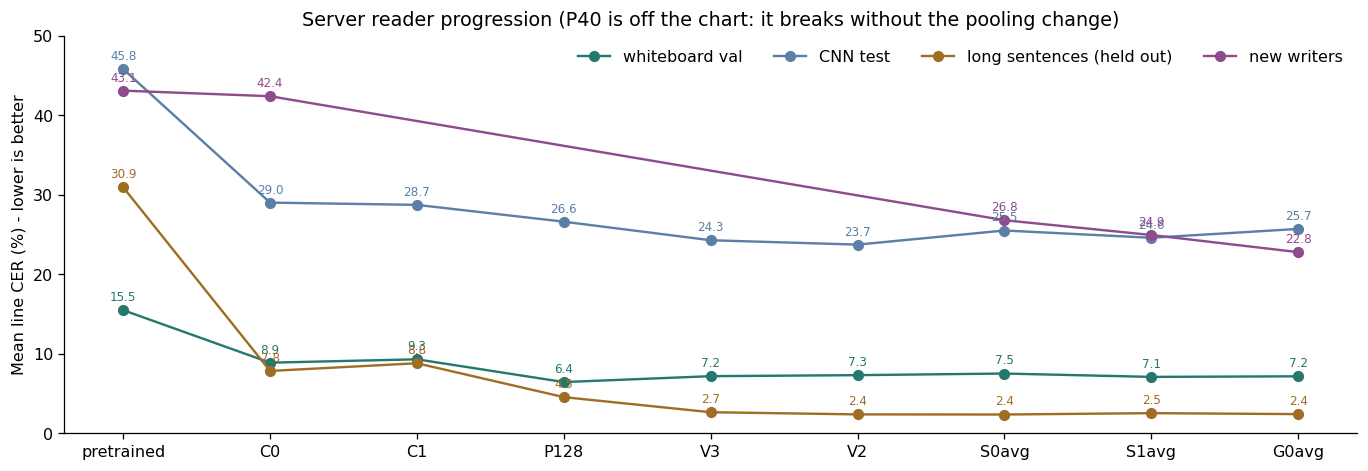

In [4]:
STEPS = [('C0', 'pretrained', 'fine-tune on our crops (original recipe)'),
         ('C1', 'C0', '+ our pre-made augmented copies'),
         ('P40', 'C1', 'wider input (64x1024) only, still 40 positions'),
         ('P128', 'P40', 'width/8 training pooling'),
         ('P128', 'C1', 'wider input + pooling together (our recipe)'),
         ('V3', 'P128', '+ lines that need more than 40 positions'),
         ('V2', 'V3', 'remove the augmented copies again'),
         ('S0avg', 'V2', 'remove the 64 teammate crops (clean baseline)'),
         ('S1avg', 'S0avg', 'stage-wise learning rates'),
         ('S2avg', 'S0avg', 'focal CTC'),
         ('S3avg', 'S0avg', 'stage-wise LR + focal CTC'),
         ('G0avg', 'S0avg', 'guidance off')]
rows = [{'step': f'{b} -> {a}', 'what changes': w, **{st: cell(a, b, st) for st in ['whiteboard val', 'CNN test', 'long sentences (held out)', 'new writers']}}
        for a, b, w in STEPS]
display(pd.DataFrame(rows).set_index('step'))

MAIN = ['pretrained', 'C0', 'C1', 'P128', 'V3', 'V2', 'S0avg', 'S1avg', 'G0avg']
fig, ax = plt.subplots(figsize=(12, 4.2))
for st, col in zip(['whiteboard val', 'CNN test', 'long sentences (held out)', 'new writers'], ['#26786c', '#5b7fa6', '#a06d25', '#8e4b8e']):
    xs = [i for i, m in enumerate(MAIN) if (m, st) in MEAN.index]; ys = [MEAN[(MAIN[i], st)] for i in xs]
    ax.plot(xs, ys, marker='o', color=col, label=st)
    for x, y in zip(xs, ys): ax.annotate(f'{y:.1f}', (x, y), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=7.5, color=col)
ax.set_xticks(range(len(MAIN))); ax.set_xticklabels(MAIN)
ax.set(ylabel='Mean line CER (%) - lower is better', ylim=(0, 50), title='Server reader progression (P40 is off the chart: it breaks without the pooling change)')
ax.legend(frameon=False, ncol=4); fig.tight_layout(); plt.show()

**How to read it**

- **Our data is the biggest step.** pretrained → C0 lowers the error by about 7 points on validation, 17 on the CNN board and 23 on held-out sentences. The price is general handwriting (IAM gets worse): the model specialises in whiteboards.
- **Pre-made augmented copies add nothing.** C0 → C1 and V3 → V2 both show it: PaddleOCR's own random augmentation already covers what the copies add.
- **The wider input and the pooling change only work together.** The wider input alone breaks the model (P40). With the pooling change, the combined step C1 → P128 is a real but modest gain of about 3 points on validation, and it lets the model train on long lines.
- **Long lines** help the CNN board and the held-out sentences by about 2 points.
- **Training strategies** (S1, S2, S3, guidance off) do not change the familiar boards beyond noise. Section 4 looks at them with two seeds, and section 5 at unfamiliar handwriting, where guidance off stands out.

## 4. Training strategies, two seeds each (S0–S3, G0)

The rule was **fixed before training**: a change "helps" only if the whiteboard-validation CER, averaged over the two seeds, is better with the whole 95 % interval below zero **and** both seeds point the same way. The second table shows how much a result moves from seed randomness alone.

In [5]:
sv = json.loads((A / 'results_strategies_s0s3/results/summary.json').read_text())['comparisons']
gv = json.loads((A / 'results_guide_vs_s0/summary.json').read_text())['comparisons']
prim = []
for t, what, src in [('S1', 'stage-wise learning rates', sv), ('S2', 'focal CTC', sv), ('S3', 'S1 + S2', sv), ('G0', 'guidance off', gv)]:
    v = src[f'primary {t}']
    s1 = src[f'whiteboard val: {t} vs S0']['diff']; s2 = src[f'whiteboard val: {t}s2 vs S0s2']['diff']
    prim.append({'setting': t, 'change': what, 'seed 1 (pp)': 100 * s1, 'seed 2 (pp)': 100 * s2, 'mean (pp)': 100 * v['diff'],
                 '95% interval': f"{100 * v['lo']:+.2f} .. {100 * v['hi']:+.2f}", 'decision': 'helps' if v['verdict'] == 'helps' else 'not established',
                 'new writers, mean of 2 seeds (pp)': cell(f'{t}avg', 'S0avg', 'new writers')})
display(pd.DataFrame(prim).set_index('setting').round(2))
noise = pd.DataFrame({st: {'S0 seed 2 - seed 1': MEAN[('S0s2', st)] - MEAN[('S0', st)], 'G0 seed 2 - seed 1': MEAN[('G0s2', st)] - MEAN[('G0', st)]}
                      for st in SETS}).round(2)
display(Markdown('**Seed noise (same recipe, different seed), points:**')); display(noise)

,change,seed 1 (pp),seed 2 (pp),mean (pp),95% interval,decision,"new writers, mean of 2 seeds (pp)"
setting,,,,,,,
S1,stage-wise learning rates,-0.66,-0.18,-0.42,-0.85 .. +0.12,not established,"-1.86 [-3.39, -0.75] better"
S2,focal CTC,-0.40,-0.14,-0.27,-0.78 .. +0.26,not established,"-0.32 [-1.45, +0.65]"
S3,S1 + S2,-0.25,-0.40,-0.32,-0.82 .. +0.45,not established,"-0.82 [-2.45, +0.29]"
G0,guidance off,-0.12,-0.57,-0.35,-0.77 .. +0.22,not established,"-4.01 [-5.69, -2.86] better"


**Seed noise (same recipe, different seed), points:**

,whiteboard val,CNN test,long sentences (held out),new writers,IAM val
S0 seed 2 - seed 1,0.01,-2.64,0.07,-1.19,-0.57
G0 seed 2 - seed 1,-0.44,-0.49,0.03,-3.98,-4.43


**Reading:** no strategy met the rule on the familiar boards. **Guidance off (G0)** is the one with a clear effect elsewhere: about **4 points better on the two new writers, in both seeds** (section 5). Stage-wise learning rates (S1) gave a smaller new-writer gain; S1 is the recipe the final model uses.

**Loss weights (checked on the mobile reader, 12 Nov):** with guidance off, lowering the NRTR weight to 0.5 made new writers about 1.8 points worse in both seeds, and raising it to 2.0 changed nothing. So CTC 1.0 / NRTR 1.0 is kept; no server weight runs were made.

## 5. Unfamiliar handwriting

Two sets, both small, so read them as **evidence, not proof**:

1. **New writers (7 Nov):** 160 crops from two people (JH and DS). It is unseen by S0–S3 and G0, because those runs leave out the 64 teammate crops. It was studied crop by crop when comparing models, so it is partly development data now.
2. **Fresh boards (11 Nov):** 152 crops of 16 writings on 5 boards. Read on the CPU with the app's recognition runtime (same resizing and decoding). **The writer is not recorded yet.** If the writer is in V2's teammate crops or the teammate's dataset, then V2's and S1his's lead on this set is partly familiarity. Intervals resample whole writings (16 groups).

In [6]:
fr = pd.read_csv(A / 'board2notes_freshwriter_test_20261111/scores_server_models.csv', keep_default_na=False)
pv = fr.pivot_table(index='id', columns='model', values='cer')
for b in ('S0', 'S1', 'G0'): pv[f'{b}avg'] = (pv[b] + pv[f'{b}s2']) / 2
writing = fr.drop_duplicates('id').set_index('id').writing; board = fr.drop_duplicates('id').set_index('id').board
def fboot(a, b, n=10000):
    d = (pv[a] - pv[b]); G = [g.values for _, g in d.groupby(writing)]; mean = lambda gs: sum(map(sum, gs)) / sum(map(len, gs)); rng = random.Random(0)
    s = sorted(mean([G[rng.randrange(len(G))] for _ in G]) for _ in range(n))
    return f'{100 * mean(G):+.2f} [{100 * s[int(.025 * n)]:+.2f}, {100 * s[int(.975 * n) - 1]:+.2f}]'
fm = ['S0avg', 'S1avg', 'G0avg', 'V2', 'S1his']
tab = pd.DataFrame({'new writers (JH, DS)': [MEAN.get((m, 'new writers'), np.nan) for m in fm],
                    'fresh boards, all 152': [100 * pv[m].mean() for m in fm],
                    **{f'board {b}': [100 * pv[m][board == b].mean() for m in fm] for b in 'ABCDE'}}, index=fm)
display(Markdown('**Mean line CER (%)** (S0, S1, G0 = mean of two seeds; V2 was not scored on the new-writer set on the GPU; S1his trained on JH and DS, so it is not scored on that set):'))
display(tab.round(2))
comp = [('G0avg', 'S0avg', 'guidance off'), ('S1avg', 'S0avg', 'stage-wise LR'), ('G0', 'S0', 'guidance off, seed 1'), ('G0s2', 'S0s2', 'guidance off, seed 2'),
        ('S0s2', 'S0', 'seed noise (same recipe)'), ('V2', 'S0avg', '+ 64 teammate crops'), ('S1his', 'S1avg', "teammate's dataset (many more writers)")]
display(Markdown('**Fresh boards, A - B in points (95% interval over the 16 writings):**'))
display(pd.DataFrame([{'comparison': f'{a} - {b}', 'what': w, 'difference': fboot(a, b),
                       'new writers (JH, DS)': cell(a, b, 'new writers')} for a, b, w in comp]).set_index('comparison'))

**Mean line CER (%)** (S0, S1, G0 = mean of two seeds; V2 was not scored on the new-writer set on the GPU; S1his trained on JH and DS, so it is not scored on that set):

,"new writers (JH, DS)","fresh boards, all 152",board A,board B,board C,board D,board E
S0avg,26.79,12.38,16.61,8.59,3.45,8.90,6.54
S1avg,24.93,11.49,14.57,13.27,6.31,8.02,5.77
G0avg,22.77,9.13,10.07,11.35,5.24,9.39,6.05
V2,NaN,5.62,4.27,10.48,1.19,8.73,5.75
S1his,NaN,4.58,4.13,1.39,0.00,7.54,5.71


**Fresh boards, A - B in points (95% interval over the 16 writings):**

,what,difference,"new writers (JH, DS)"
comparison,,,
G0avg - S0avg,guidance off,"-3.25 [-5.98, -0.61]","-4.01 [-5.69, -2.86] better"
S1avg - S0avg,stage-wise LR,"-0.90 [-3.94, +2.90]","-1.86 [-3.39, -0.75] better"
G0 - S0,"guidance off, seed 1","-5.44 [-10.00, -0.66]","-2.62 [-4.85, -0.97] better"
G0s2 - S0s2,"guidance off, seed 2","-1.06 [-4.98, +3.21]","-5.41 [-7.60, -3.73] better"
S0s2 - S0,seed noise (same recipe),"-3.72 [-8.81, +1.04]","-1.19 [-3.22, +0.43]"
V2 - S0avg,+ 64 teammate crops,"-6.77 [-10.74, -2.60]",
S1his - S1avg,teammate's dataset (many more writers),"-6.91 [-14.42, -2.15]",


**Reading:** guidance off helps unfamiliar handwriting in the two new writers (about −4 points, both seeds) and on the fresh boards (about −3 points). On the fresh boards that gain comes almost entirely from board A and from seed 1, and seed noise there is as large as the effect. So the direction is consistent, but it is **not proven** for the final recipe. Models trained on **more writers** (V2, S1his) read the fresh boards much better. That is the largest effect we have measured on unfamiliar handwriting, provided the board writer is not already in their data.

## 6. The final model: S1his on the teammate's 80:10:10 split

The S1 recipe, trained on the teammate's leak-fixed split. Validation (179 crops) picked the checkpoint and the test (169 crops) was scored once. Different data and test set: **do not compare these numbers with the tables above.** His dataset contains our CNN and validation boards and the JH/DS writers, so S1his is never scored on our sets.

In [7]:
his = json.loads((A / 'results_server_his_20261110/results/summary.json').read_text())
hs = his['summary']
t = pd.DataFrame({st: {m: 100 * hs[f'{m} | {st}']['mean_line_CER'] for m in ('pretrained', 'S1his')} for st in ('his val', 'his test')})
t.loc['S1his - pretrained'] = t.loc['S1his'] - t.loc['pretrained']
display(t.rename(columns=lambda c: c + ' CER (%)').round(2))
v = his['comparisons']['his test: S1his vs pretrained']
display(Markdown(f"Test: **{100 * v['diff']:+.2f} points**, 95% interval {100 * v['lo']:+.2f} .. {100 * v['hi']:+.2f} (whole board photos resampled)."))

,his val CER (%),his test CER (%)
pretrained,18.24,16.90
S1his,6.21,7.04
S1his - pretrained,-12.02,-9.86


Test: **-9.86 points**, 95% interval -12.96 .. -6.75 (whole board photos resampled).

## 7. What contributed (server reader)

| change | effect on familiar boards | effect on unfamiliar handwriting | status |
|---|---|---|---|
| **fine-tune on our whiteboard crops** | very large (CNN about −17, held-out sentences about −23) | large | established |
| our recipe: wider input **with** width/8 pooling | about −3 on validation, −4 on long sentences | — | established (same lines, one seed) |
| wider input **without** the pooling change | breaks the model (+45) | — | established: the two changes belong together |
| long training lines | about −2 on CNN and long sentences | — | one seed |
| pre-made augmented copies | none (twice) | — | no benefit |
| stage-wise learning rates (S1) | within noise | small gain on new writers | kept in the final recipe |
| focal CTC (S2, S3) | within noise | — | not kept |
| guidance off (G0) | within noise | about −4 (JH/DS, both seeds), about −3 (fresh boards, unstable) | promising; not yet tested on the final recipe |
| NRTR weight 0.5 / 2.0 (mobile) | 0.5 slightly better, 2.0 no change | 0.5 worse | keep 1.0 / 1.0 |
| **more writers in training** (V2, S1his) | — | about −7 on fresh boards | largest effect; writer overlap still to be checked |

**Final model now:** S1his (S1 recipe on the teammate's split; guidance on; CTC 1.0 / NRTR 1.0). **Next, if trained:** S1his seed 2 and G1his (guidance off) with two seeds, decided on his validation set by the rule above.

**Limits:** most data steps have one seed; the unfamiliar-handwriting sets are small (2 writers; 16 writings); the fresh boards' writer is not yet recorded; intervals cover which crops are in a set, not training randomness or other writers.